# Phase 1 Complete Guide — Understanding the SDSS Galaxy Atlas

Welcome! This notebook explains **everything built in Phase 1** in plain, accessible language, along with all runnable Python code to explore the data, inspect the database, and plot the scientific results.

## The Big Picture
We are building an open-source **Galaxy Encyclopedia & Machine Learning Atlas** using real telescope observations from the **Sloan Digital Sky Survey (SDSS DR17)**:
- **Phase 1 (Completed)**: Download real galaxy measurements via SQL, calculate physical properties (real size in kiloparsecs, true brightness, colors, light concentration), and store them cleanly in a local SQLite database (`data/galaxy_atlas.db`).
- **Phase 2 (Next)**: Download real color photos and scientific FITS images of those galaxies.
- **Phase 3 (Later)**: Train machine learning models (a tabular Random Forest + a Deep Learning CNN) to classify each galaxy's shape into **Hubble Sequence** categories (Elliptical, Lenticular/Edge-on, Barred Spiral, Unbarred Spiral, Irregular/Merger).
- **Phase 4 (Final)**: Build an interactive website dashboard where you can click on charts and inspect galaxy photos.

---
## Step 1: Setup, Configuration & Cosmology (`src/config.py`)

All paths, cosmology settings, and telescope filters live in `ProjectConfig`:
- **Redshift (`0.02 <= z <= 0.10`)**: Measures how far away a galaxy is due to the expansion of the Universe (roughly 85 to 450 million light-years away — close enough to see galaxy shapes clearly).
- **Brightness Cut (`modelMag_r < 17.77`)**: In astronomy, *smaller* magnitudes mean *brighter* galaxies. `17.77` is the standard SDSS completeness limit.
- **FlatLambdaCDM Cosmology ($H_0 = 70\,\mathrm{km\,s^{-1}\,Mpc^{-1}}$, $\Omega_{m0} = 0.3$)**: Lets `astropy` convert each galaxy's redshift into its physical distance.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.acquisition import SDSSCatalogFetcher
from src.analysis import (
    load_galaxy_zoo_agreement,
    load_morphology_summary,
    load_redshift_binned_stats,
    load_scaling_relations_sample,
    plot_color_magnitude,
    plot_concentration_morphology,
    plot_mass_size_relation,
)
from src.config import ProjectConfig
from src.database import GalaxyDatabase

config = ProjectConfig()
fetcher = SDSSCatalogFetcher(config)

print("Database path: ", config.db_path)
print("Cosmology:     ", config.cosmology)
print("Selection cuts:", json.dumps(config.quality_cuts_metadata(), indent=2))

Database path:  C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\galaxy_atlas.db
Cosmology:      FlatLambdaCDM(H0=70.0 km / (Mpc s), Om0=0.3, Tcmb0=0.0 K, Neff=3.04, m_nu=None, Ob0=0.0)
Selection cuts: {
  "data_release": 17,
  "z_min": 0.02,
  "z_max": 0.1,
  "modelMag_r_max": 17.77,
  "photo_type": 3,
  "spec_class": "GALAXY",
  "zWarning": 0,
  "fracDeV_r_early_threshold": 0.5
}


---
## Step 2: The SDSS DR17 SQL Query (`src/acquisition.py`)

Our fetcher joins four official SDSS tables in one SQL query:
1. **`PhotoObj` (`p`)**: Coordinates (`ra`, `dec`), brightness in 5 color bands (`u, g, r, i, z`), radii (`petroRad_r`, `petroR50_r`, `petroR90_r`), and `fracDeV_r` (a 0–1 score measuring how smooth/elliptical vs disk-like the galaxy light is).
2. **`SpecObj` (`s`)**: Confirmed galaxy classification (`s.class = 'GALAXY'`), accurate redshift (`z`), and clean quality flag (`zWarning = 0`).
3. **`galSpecExtra` (`gse`)**: Stellar mass (`lgm_tot_p50`, in $\log_{10}(M_\star / M_\odot)$) and star formation rate (`sfr_tot_p50`, stored as `log_sfr` in $\log_{10}(M_\odot/\mathrm{yr})$).
4. **`LEFT JOIN zooSpec` (`z`)**: Citizen-science **Galaxy Zoo** visual votes (`p_el_debiased` for ellipticals, `p_cs_debiased` for spirals). Using `LEFT JOIN` keeps galaxies even if they do not have Galaxy Zoo votes.

Notice we route `astroquery.sdss.SDSSClass` to `/dr17/SkyServerWS/SearchTools/SqlSearch` because SDSS DR17's older `x_results.aspx` page returns `403 Forbidden`.

In [2]:
TOP_N = 100  # Use 2500 when ready to download the full Phase 1 catalog
print(fetcher.build_sql_query(top_n=TOP_N))

SELECT TOP 100
    p.objID,
    p.ra,
    p.dec,
    s.z,
    p.modelMag_u,
    p.modelMag_g,
    p.modelMag_r,
    p.modelMag_i,
    p.modelMag_z,
    p.petroRad_r,
    p.petroR50_r,
    p.petroR90_r,
    p.fracDeV_r,
    gse.lgm_tot_p50,
    gse.sfr_tot_p50,
    z.p_el_debiased,
    z.p_cs_debiased
FROM PhotoObj AS p
INNER JOIN SpecObj AS s
    ON s.bestObjID = p.objID
INNER JOIN galSpecExtra AS gse
    ON gse.specObjID = s.specObjID
LEFT JOIN zooSpec AS z
    ON z.objid = p.objID
WHERE
    p.type = 3
    AND s.class = 'GALAXY'
    AND s.zWarning = 0
    AND s.z BETWEEN 0.02 AND 0.1
    AND p.modelMag_r < 17.77
ORDER BY p.objID


---
## Step 3: Cleaning Sentinel Values & Computing Physical Parameters

Raw SDSS data sometimes contains error placeholders like `-9999`. Our `clean_and_derive()` method removes bad rows and calculates real physical quantities:
- **`color_gr` (`g - r`) & `color_ug` (`u - g`)**: Higher values = redder, older stars; lower values = bluer, actively star-forming galaxies.
- **`abs_mag_r` ($M_r$)**: True brightness after correcting for distance using `cosmo.distmod(z)`.
- **`re_kpc`**: Physical half-light radius in **kiloparsecs** (1 kpc $\approx$ 3,260 light-years), computed from `petroR50_r`.
- **`concentration` ($R_{90}/R_{50}$)**: How concentrated the light is at the center (ellipticals usually have $C > 2.6$, spirals $C < 2.6$).
- **`morph_proxy`**: Simple baseline morphology label (`'early'` if `fracDeV_r >= 0.5`, else `'late'`).

Leave `RUN_LIVE_FETCH = False` to explore the already-populated local database immediately, or flip it to `True` to query SDSS DR17 live.

In [3]:
RUN_LIVE_FETCH = False  # Set to True to fetch fresh data from SDSS DR17

if RUN_LIVE_FETCH or not config.db_path.exists():
    result = fetcher.run_pipeline(top_n=TOP_N)
    print(f"Ingested {result['clean_count']}/{result['raw_count']} clean galaxies into {result['db_path']}")
else:
    print(f"Loaded existing database: {config.db_path}")

Loaded existing database: C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\galaxy_atlas.db


---
## Step 4: Exploring the Normalized SQLite Database (`src/database.py`)

`data/galaxy_atlas.db` contains four linked tables plus one dashboard view:
- **`galaxies`**: Every galaxy's measurements stored strictly as unitless `REAL` numbers.
- **`images`**: Ready for Phase 2 galaxy cutout paths.
- **`predictions`**: Ready for Phase 3 ML/CNN classifications.
- **`metadata`**: Stores the exact SQL query, cosmology, selection cuts, and row counts.
- **`v_galaxy_dashboard`**: Unified SQL view combining `galaxies` with the latest image and ML prediction.

In [4]:
with GalaxyDatabase(config.db_path) as db:
    print("Table counts:", db.get_table_counts())
    print("Metadata keys:", sorted(db.get_metadata().keys()))
    sample_preview = db.query_df(
        """
        SELECT objID, redshift, abs_mag_r, color_gr, log_stellar_mass, log_sfr, re_kpc, concentration, morph_proxy
        FROM v_galaxy_dashboard
        ORDER BY objID
        LIMIT 5
        """
    )

sample_preview

Table counts: {'galaxies': 2489, 'images': 0, 'predictions': 0, 'metadata': 8}
Metadata keys: ['clean_row_count', 'cosmology', 'dropped_row_count', 'last_retrieved_at', 'quality_cuts', 'raw_row_count', 'sdss_sql_query', 'upserted_row_count']


,objID,redshift,abs_mag_r,color_gr,log_stellar_mass,log_sfr,re_kpc,concentration,morph_proxy
0,1237645879551066262,0.032125,-18.158320,0.65768,9.295615,-0.628693,1.208103,2.503365,late
1,1237645879577936138,0.074298,-19.986390,0.70102,10.185770,-0.227703,3.869080,2.223676,late
2,1237645941824356443,0.040287,-21.219250,0.72064,10.588380,-1.241858,3.861065,3.039300,early
3,1237645942905438473,0.025475,-19.709924,0.64994,9.779433,0.027335,2.412080,2.041748,late
4,1237645942905438495,0.036167,-18.418841,0.59201,9.583373,-1.651724,2.612202,2.223273,late


---
## Step 5: Scientific Summary & Scaling Relation Plots (`src/analysis.py`)

Let's run our analytical SQL queries into Pandas and draw three classic astrophysics charts:
1. **Color–Magnitude Diagram**: Red, massive early-type galaxies (*Red Sequence*) vs bluer star-forming late-type galaxies (*Blue Cloud*).
2. **Stellar Mass–Size Relation**: How physical radius (`re_kpc`) grows with stellar mass (`log_stellar_mass`).
3. **Concentration vs Morphology**: Checking how well `early` vs `late` galaxies separate around $C = 2.6$.

,morph_proxy,galaxy_count,avg_log_stellar_mass,avg_re_kpc,avg_color_gr,avg_log_sfr,avg_concentration
0,early,1368,10.590385,3.184679,0.884450,-0.894362,2.857193
1,late,1121,10.031703,3.856701,0.649922,-0.095272,2.250398


,z_bin_start,morph_proxy,galaxy_count,avg_log_stellar_mass,avg_re_kpc,avg_color_gr,avg_log_sfr,avg_concentration
0,0.02,early,105,10.022654,2.126430,0.739222,-1.001319,2.884784
1,0.02,late,202,9.424163,2.730034,0.567120,-0.566673,2.282144
2,0.04,early,278,10.465195,2.687990,0.868021,-0.953322,2.878162
3,0.04,late,301,9.917023,3.392873,0.631221,-0.189862,2.244668
4,0.06,early,318,10.625936,3.247125,0.877411,-0.791769,2.863356
5,0.06,late,258,10.173116,4.184998,0.648732,0.052702,2.241459
6,0.08,early,667,10.714988,3.528514,0.917515,-0.901863,2.841172
7,0.08,late,360,10.367141,4.641419,0.712872,0.142275,2.243783


,morph_proxy,zoo_matched_count,avg_p_el_debiased,avg_p_cs_debiased
0,early,1051,0.492969,0.413430
1,late,857,0.153268,0.744919


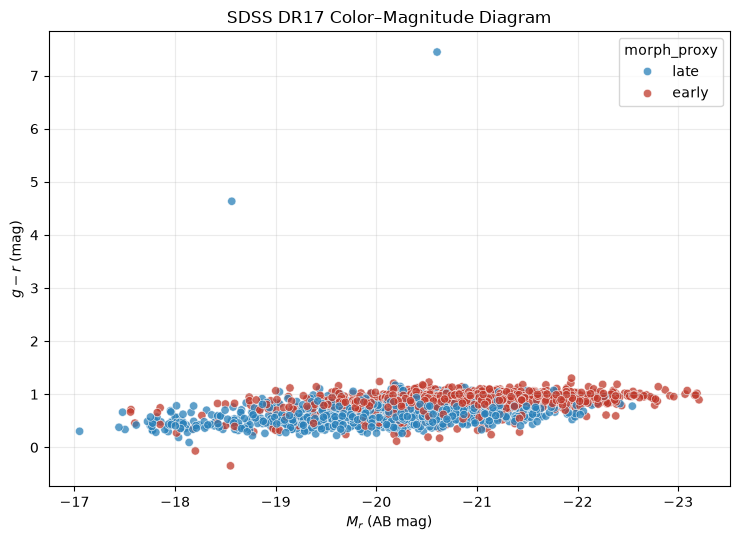

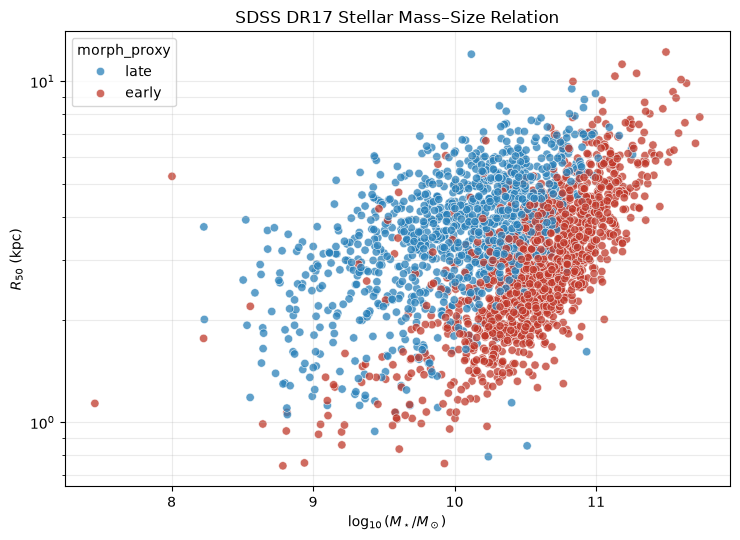

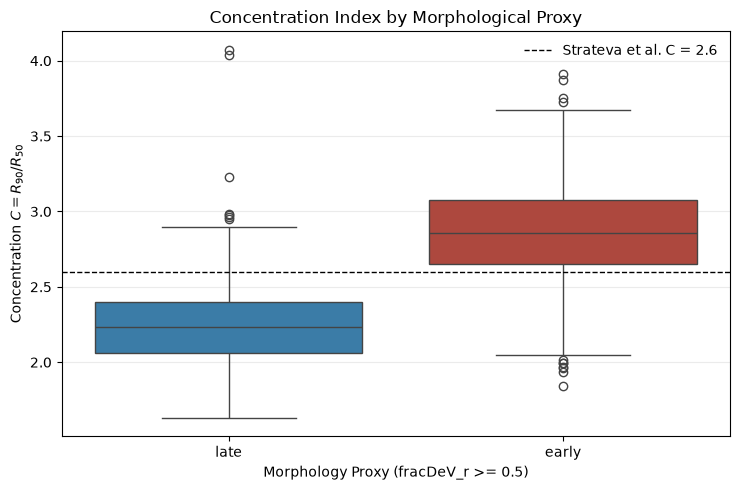

In [5]:
with GalaxyDatabase(config.db_path) as db:
    summary_df = load_morphology_summary(db)
    sample_df = load_scaling_relations_sample(db)
    z_bins_df = load_redshift_binned_stats(db, bin_width=0.02)
    zoo_df = load_galaxy_zoo_agreement(db)

display(summary_df)
display(z_bins_df)
display(zoo_df)

config.ensure_directories()
plot_color_magnitude(sample_df, config.figures_dir / "color_magnitude_diagram.png")
plot_mass_size_relation(sample_df, config.figures_dir / "mass_size_relation.png")
plot_concentration_morphology(sample_df, config.figures_dir / "concentration_morphology.png")
plt.show()